# meK-Means cluster recovery on PBMC 10k

meK-Means ([Chari, Gorin & Pachter, 2024](https://www.nature.com/articles/s43588-024-00689-2))
clusters cells by their transcriptional kinetics: it fits one set of CME parameters per
cluster and alternates between assigning each cell to the cluster whose model explains
it best and refitting the clusters.  This notebook runs it on PBMC 10k through
`MEKMeansParameters.run_mek_means`, compares the recovered clusters with the annotated
cell types, then repeats the run with the Rust fast paths switched off to show that the
Python fallback reaches the same clustering, more slowly.

Needs `example_h5ad/processed_pbmc_10k_raw.h5ad`; takes about a minute.
`mek_means_rust.ipynb` times each fast path on its own and shows the two-stage
procedure used with a technical-noise model; `docs/mek-means.md` describes the options.


In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import os, time, logging, warnings
import numpy as np
import scipy.sparse
import matplotlib.pyplot as plt
import anndata as ad
from sklearn.metrics import adjusted_rand_score, confusion_matrix
from scipy.optimize import linear_sum_assignment

from monod.cme_toolbox import CMEModel
from monod.extract_data import extract_data
from monod.inference import searchdata_from_adata
import monod.mminference as mm
from monod.mminference import MEKMeansParameters

os.makedirs('figures', exist_ok=True)
warnings.filterwarnings('ignore')
# The fits below use 15 L-BFGS-B iterations per gene on purpose, which leaves a few
# genes short of convergence each epoch; silence the per-epoch log and those notes.
logging.disable(logging.WARNING)

C_PY, C_RUST = 'steelblue', 'firebrick'
print(f'Rust fast paths available: {mm._HAS_RUST}')


Rust fast paths available: True


In [3]:
# ── Load dataset and ground-truth labels ──────────────────────────────────────
H5AD_PATH = 'example_h5ad/processed_pbmc_10k_raw.h5ad'

adata = ad.read_h5ad(H5AD_PATH)
adata.var_names_make_unique()

cell_types   = adata.obs['subclass_label'].values
unique_types, type_counts = np.unique(cell_types, return_counts=True)

print(f'Dataset: {adata.n_obs:,} cells  |  {adata.n_vars:,} genes')
print('Cell types:')
for ct, n in sorted(zip(unique_types, type_counts), key=lambda x: -x[1]):
    print(f'  {ct:20s}: {n:5,} ({100*n/adata.n_obs:.1f}%)')

Dataset: 10,997 cells  |  36,601 genes
Cell types:
  Tcells              : 5,375 (48.9%)
  Monocytes           : 3,972 (36.1%)
  Bcells              : 1,650 (15.0%)


In [4]:
# ── Gene selection and data extraction ───────────────────────────────────────
MODEL   = CMEModel('Bursty', 'None')
N_GENES = 25
K       = 3          # the three annotated cell types
EPOCHS  = 6

# The first 25 genes (file order) seen in at least 100 cells, counted on the sparse
# matrix (dense, it would be 1.6 GB).
s_sp = adata.layers['spliced']
if not scipy.sparse.issparse(s_sp):
    s_sp = scipy.sparse.csc_matrix(s_sp)
n_cells_expr = np.asarray((s_sp > 0).sum(axis=0)).ravel()
GENES = list(adata.var_names[np.where(n_cells_expr >= 100)[0][:N_GENES]])
del s_sp
print(f'Selected {N_GENES} genes expressed in ≥100 cells')

adata_ext = extract_data(
    adata, MODEL,
    dataset_name='pbmc_mek_means',
    modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
    n_genes=N_GENES, genes_to_fit=GENES,
    hist_type='unique', viz=False,
)
search_data = searchdata_from_adata(adata_ext)
n_cells = search_data.n_cells
print(f'SearchData: {search_data.n_genes} genes, {n_cells:,} cells')


Selected 25 genes expressed in ≥100 cells


SearchData: 25 genes, 10,997 cells


In [5]:
# ── Run meK-Means ─────────────────────────────────────────────────────────────
GRAD = {'max_iterations': 15, 'init_pattern': 'moments', 'num_restarts': 1}

ip = MEKMeansParameters(
    'pbmc_mek_means', MODEL,
    use_lengths=False,
    gradient_params=GRAD,
    k=K, epochs=EPOCHS,
    random_state=0,          # seeds the k-means initialization
)

t0 = time.perf_counter()
full_results = ip.run_mek_means(search_data)
t_rust = time.perf_counter() - t0

print(f'meK-Means complete in {t_rust:.1f}s  |  {len(full_results)} non-empty clusters')


meK-Means complete in 1.8s  |  3 non-empty clusters


In [6]:
# ── Per-cell cluster assignments ──────────────────────────────────────────────
def cell_assignments(results, n_cells):
    """Per-cell cluster index from a run_mek_means result list: each SearchResults
    carries .assigns (its cluster index) and .filt (True for the cells in it)."""
    out = np.full(n_cells, -1, dtype=int)
    for sr in results:
        out[sr.filt] = int(sr.assigns)
    return out


cell_assigns = cell_assignments(full_results, n_cells)
if (cell_assigns == -1).any():
    print(f'Warning: {(cell_assigns == -1).sum()} cells unassigned (empty cluster)')

unique_k, counts_k = np.unique(cell_assigns, return_counts=True)
print('Cluster sizes:')
for k, n in zip(unique_k, counts_k):
    print(f'  Cluster {k}: {n:,} cells ({100*n/n_cells:.1f}%)')


Cluster sizes:
  Cluster 0: 4,036 cells (36.7%)
  Cluster 1: 4,044 cells (36.8%)
  Cluster 2: 2,917 cells (26.5%)


In [7]:
# ── Compare with the annotated cell types ────────────────────────────────────
type_labels = sorted(unique_types)
type_to_int = {ct: i for i, ct in enumerate(type_labels)}
# extract_data may drop cells, so look the kept cells up by name.
true_labels = np.array([type_to_int[ct]
                        for ct in adata.obs.loc[adata_ext.obs_names, 'subclass_label']])

ari = adjusted_rand_score(true_labels, cell_assigns)
print(f'ARI (meK-Means vs ground truth): {ari:.3f}')
print('(0 = random assignment, 1 = perfect recovery)\n')

cm = confusion_matrix(true_labels, cell_assigns, labels=range(K))
print(f"{'':>12s}  " + '  '.join(f'Cluster {k}' for k in range(K)))
for i, ct in enumerate(type_labels):
    print(f'{ct:>12s}  ' + '  '.join(f'{cm[i, j]:9,d}' for j in range(K)))


ARI (meK-Means vs ground truth): 0.327
(0 = random assignment, 1 = perfect recovery)

              Cluster 0  Cluster 1  Cluster 2
      Bcells      1,265        310         75
   Monocytes      1,125        193      2,654
      Tcells      1,646      3,541        188


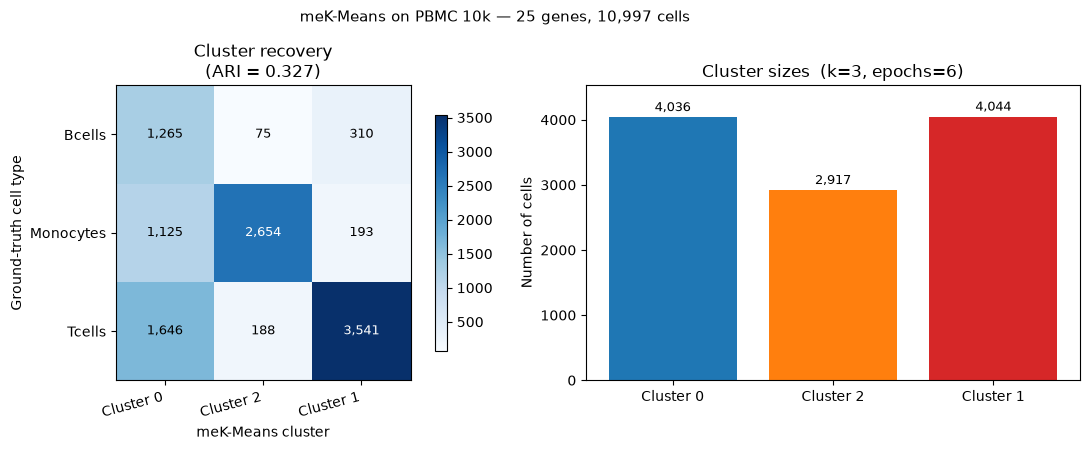

In [8]:
# ── Confusion matrix figure ───────────────────────────────────────────────────
def plot_cm(ax, mat, row_labels, col_labels, title):
    """Annotated confusion matrix on ax."""
    im = ax.imshow(mat, cmap='Blues')
    ax.set_xticks(range(len(col_labels))); ax.set_xticklabels(col_labels, rotation=15, ha='right')
    ax.set_yticks(range(len(row_labels))); ax.set_yticklabels(row_labels)
    ax.set_title(title)
    thresh = mat.max() * 0.5
    for i in range(len(row_labels)):
        for j in range(len(col_labels)):
            ax.text(j, i, f'{mat[i, j]:,}', ha='center', va='center',
                    color='white' if mat[i, j] > thresh else 'black', fontsize=9)
    ax.figure.colorbar(im, ax=ax, shrink=0.8)


# Order the clusters so the dominant cell type runs down the diagonal (cosmetic:
# cluster indices are arbitrary and the ARI does not change).
_, col_ind = linear_sum_assignment(-cm)
cm_aligned = cm[:, col_ind]
cluster_labels_aligned = [f'Cluster {j}' for j in col_ind]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_cm(axes[0], cm_aligned, type_labels, cluster_labels_aligned,
        f'Cluster recovery\n(ARI = {ari:.3f})')
axes[0].set_xlabel('meK-Means cluster'); axes[0].set_ylabel('Ground-truth cell type')

ax = axes[1]
bars = ax.bar(cluster_labels_aligned, counts_k[col_ind],
              color=plt.cm.tab10(np.linspace(0, 0.3, K)))
for b, n in zip(bars, counts_k[col_ind]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 50,
            f'{n:,}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Number of cells')
ax.set_title(f'Cluster sizes  (k={K}, epochs={EPOCHS})')
ax.set_ylim(0, counts_k.max() * 1.12)

fig.suptitle(f'meK-Means on PBMC 10k — {N_GENES} genes, {n_cells:,} cells', fontsize=11)
fig.tight_layout()
plt.savefig('figures/mek_means_confusion.png', dpi=150, bbox_inches='tight')
plt.show()


## The same run without the Rust fast paths

Four steps of the EM loop have Rust implementations in `monod_core`, used automatically
when the extension is installed:

| Step | Rust function | Python fallback |
|---|---|---|
| Q initialization | `initialize_q_kmeans` | sklearn `KMeans` |
| E-step | `e_step_2d` | a loop of `eval_model_pss` calls over clusters × genes |
| Cell partitioning | `partition_searchdata_2d` | NumPy filtering and histogram rebuild per cluster |
| M-step | `optimize_genes_2d_sd` | scipy L-BFGS-B, gene by gene |

Setting `mminference._HAS_RUST = False` switches the E-step and the partitioning to
their fallbacks; the Python partition returns Python `SearchData` objects, so the
M-step then runs in scipy as well (`use_rust_lbfgsb=False` in `gradient_params` says
so explicitly).  The k-means initialization is left on so that both runs start from the
same partition (sklearn and the Rust k-means draw from different random streams).
Each `eval_model_pss` and KLD evaluation inside the fallback still uses the Rust
kernels; what the fallback loses is the parallel, GIL-free loops.  For the extension
switched off entirely see `rust_benchmarks.ipynb`, section 4.


In [9]:
# ── Python fallback run ──────────────────────────────────────────────────────
ip_py = MEKMeansParameters(
    'pbmc_mek_means_py', MODEL,
    use_lengths=False,
    gradient_params={**GRAD, 'use_rust_lbfgsb': False},
    k=K, epochs=EPOCHS,
    random_state=0,
)

_rust_was = mm._HAS_RUST
mm._HAS_RUST = False
try:
    t0 = time.perf_counter()
    results_py = ip_py.run_mek_means(search_data)
    t_py = time.perf_counter() - t0
finally:
    mm._HAS_RUST = _rust_was

assigns_py = cell_assignments(results_py, n_cells)
ari_py = adjusted_rand_score(true_labels, assigns_py)
print(f'Rust fast paths : {t_rust:5.1f}s   ARI = {ari:.3f}')
print(f'Python fallback : {t_py:5.1f}s   ARI = {ari_py:.3f}')
print(f'Speedup: {t_py / t_rust:.1f}×')


Rust fast paths :   1.8s   ARI = 0.327
Python fallback :   4.5s   ARI = 0.328
Speedup: 2.5×


Cells placed in the same cluster by both runs: 99.8%


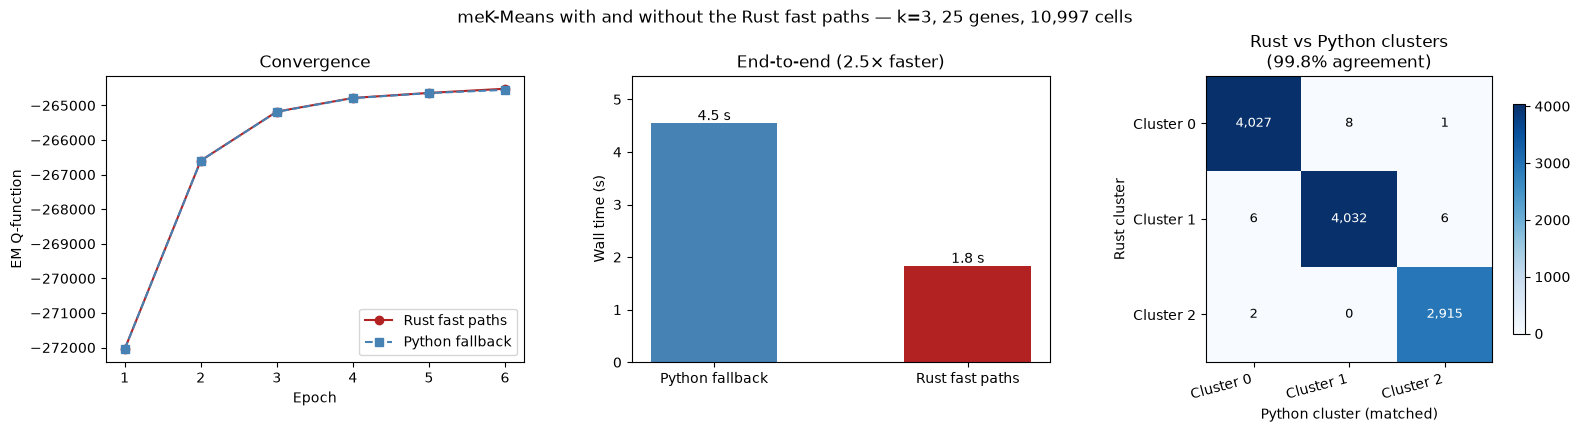

In [10]:
# ── Same clustering? ─────────────────────────────────────────────────────────
# Cluster indices are arbitrary: match the Python clusters to the Rust ones first.
cross_raw = confusion_matrix(cell_assigns, assigns_py, labels=range(K))
_, col_ind_py = linear_sum_assignment(-cross_raw)
relabel = np.empty(K, dtype=int)
relabel[col_ind_py] = np.arange(K)
assigns_py_aligned = relabel[assigns_py]
agreement = (cell_assigns == assigns_py_aligned).mean()
print(f'Cells placed in the same cluster by both runs: {agreement:.1%}')

# The EM Q-function per epoch is stored on every cluster's SearchResults (all_qs,
# one row per grid point; here there is one).
q_rust = np.asarray(full_results[0].all_qs)[0]
q_py   = np.asarray(results_py[0].all_qs)[0]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
ax.plot(np.arange(1, len(q_rust) + 1), q_rust, 'o-',  color=C_RUST, label='Rust fast paths')
ax.plot(np.arange(1, len(q_py) + 1),   q_py,   's--', color=C_PY,   label='Python fallback')
ax.set_xlabel('Epoch'); ax.set_ylabel('EM Q-function'); ax.set_title('Convergence'); ax.legend()

ax = axes[1]
bars = ax.bar(['Python fallback', 'Rust fast paths'], [t_py, t_rust],
              color=[C_PY, C_RUST], width=0.5)
for b, t in zip(bars, [t_py, t_rust]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f'{t:.1f} s', ha='center', va='bottom')
ax.set_ylabel('Wall time (s)'); ax.set_title(f'End-to-end ({t_py/t_rust:.1f}× faster)')
ax.set_ylim(0, max(t_py, t_rust) * 1.2)

cluster_labels = [f'Cluster {k}' for k in range(K)]
plot_cm(axes[2], confusion_matrix(cell_assigns, assigns_py_aligned, labels=range(K)),
        cluster_labels, cluster_labels, f'Rust vs Python clusters\n({agreement:.1%} agreement)')
axes[2].set_ylabel('Rust cluster'); axes[2].set_xlabel('Python cluster (matched)')

fig.suptitle(f'meK-Means with and without the Rust fast paths — '
             f'k={K}, {N_GENES} genes, {n_cells:,} cells')
fig.tight_layout()
plt.savefig('figures/mek_means_rust_vs_python.png', dpi=150, bbox_inches='tight')
plt.show()


Up to optimizer round-off the two runs follow the same Q-function trajectory and agree
on the clustering; only the wall time differs.  `mek_means_rust.ipynb` shows what each
fast path contributes; `docs/mek-means.md` covers the result objects (`aic_per_cell`
for choosing k, `random_state`, `em_tol`).
